threads: 6
GPU: NVIDIA RTX A400 (3.7 GB)
pinned to cores 0-15
train: (50000, 3, 32, 32)   test: (10000, 3, 32, 32)


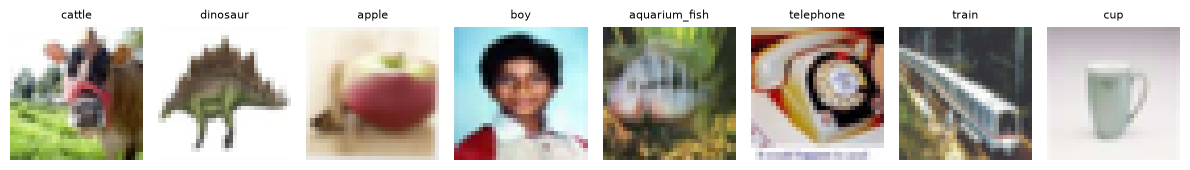

In [6]:
#N1: imports + threads + load CIFAR-100 (pickled files: meta, train, test), kept in colour

import os
N_THREADS = 6                                    # Baby-U: 12 cores, the GPU does the training (6 leaves room for a 2nd notebook)
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
    torch.backends.cuda.matmul.allow_tf32 = True     # RTX 30xx: faster float32 matrix products, same results to ~3 digits
    torch.backends.cudnn.allow_tf32 = True
else:
    print("no GPU found: running on the CPU (much slower)")

CPU_SLOT = 0     # only used on the 64-core Fatbaby: 0 -> cores 0-15, 1 -> 16-31, ... (Baby-U skips this)
if (os.cpu_count() or 0) >= 64:
    os.sched_setaffinity(0, range(16 * CPU_SLOT, 16 * CPU_SLOT + 16))
    print(f"pinned to cores {16 * CPU_SLOT}-{16 * CPU_SLOT + 15}")

BASE = '/home/worker/Downloads/talha/week6/cifar notebooks/cifar-100/'   # CHANGE to the folder on Baby-U that holds meta, train, test

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(os.path.join(BASE, 'meta'))
train = unpickle(os.path.join(BASE, 'train'))
test  = unpickle(os.path.join(BASE, 'test'))
fine_names = meta['fine_label_names']            # 100 names, index = fine label

# each row = 1024 red + 1024 green + 1024 blue values -> keep colour: [N, 3, 32, 32] (no grayscale, no resizing)
x_train_all = np.asarray(train['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_train_all = np.array(train['fine_labels'])
x_test_all  = np.asarray(test['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_test_all  = np.array(test['fine_labels'])
print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    axes[k].imshow(x_train_all[k].transpose(1, 2, 0))
    axes[k].set_title(fine_names[y_train_all[k]], fontsize=8)
    axes[k].axis('off')
plt.tight_layout(); plt.show()

In [7]:
#N2: the 100 classes: ONE problem, the label of an image is its CIFAR-100 class number 0-99 (no relabelling to 0-4)

assert len(fine_names) == 100
for start in range(0, 100, 5):
    print("   ".join(f"{i:2d} {fine_names[i]:13s}" for i in range(start, start + 5)))
print("\n1 problem with all 100 classes")

 0 apple            1 aquarium_fish    2 baby             3 bear             4 beaver       
 5 bed              6 bee              7 beetle           8 bicycle          9 bottle       
10 bowl            11 boy             12 bridge          13 bus             14 butterfly    
15 camel           16 can             17 castle          18 caterpillar     19 cattle       
20 chair           21 chimpanzee      22 clock           23 cloud           24 cockroach    
25 couch           26 crab            27 crocodile       28 cup             29 dinosaur     
30 dolphin         31 elephant        32 flatfish        33 forest          34 fox          
35 girl            36 hamster         37 house           38 kangaroo        39 keyboard     
40 lamp            41 lawn_mower      42 leopard         43 lion            44 lizard       
45 lobster         46 man             47 maple_tree      48 motorcycle      49 mountain     
50 mouse           51 mushroom        52 oak_tree        53 orange    

In [8]:
#N3: building ONE dataset: all 100 classes, colour 3x32x32, standardized per colour channel

TUNING        = False    # True: keep 50 training images per class aside and test on them (to choose lr / epochs);
                         #       the real test set is then never touched. False: train on all 50,000, test on the 10,000 test images.
VAL_PER_CLASS = 50

rng = np.random.default_rng(0)    # fixed: the same held-out images every time
xs_tr, ys_tr, xs_te, ys_te = [], [], [], []
for label in range(100):                                             # label = CIFAR-100 class number 0-99
    tr = x_train_all[y_train_all == label]                           # 500 training images of this class
    te = x_test_all[y_test_all == label]                             # 100 test images of this class
    if TUNING:
        perm = rng.permutation(len(tr))
        te, tr = tr[perm[:VAL_PER_CLASS]], tr[perm[VAL_PER_CLASS:]]
    xs_tr.append(tr); ys_tr.append(np.full(len(tr), label))
    xs_te.append(te); ys_te.append(np.full(len(te), label))
x_tr = torch.tensor(np.concatenate(xs_tr), dtype=torch.float32)      # [50000, 3, 32, 32]
x_te = torch.tensor(np.concatenate(xs_te), dtype=torch.float32)      # [10000, 3, 32, 32]
mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)                        # one mean and std per colour channel,
std  = x_tr.std(dim=(0, 2, 3), keepdim=True)                         # from all the training images (one problem)
X_tr = ((x_tr - mean) / std)[None]                                   # [1, 50000, 3, 32, 32]: 1 problem
X_te = ((x_te - mean) / std)[None]                                   # [1, 10000, 3, 32, 32]
Y_tr = torch.tensor(np.concatenate(ys_tr), dtype=torch.long)[None]   # [1, 50000], labels 0-99
Y_te = torch.tensor(np.concatenate(ys_te), dtype=torch.long)[None]   # [1, 10000]
del x_tr, x_te

print(f"1 problem, 100 classes   train {X_tr.shape[1]}  test {X_te.shape[1]}  "
      f"channel means {[round(v, 1) for v in mean.flatten().tolist()]}  stds {[round(v, 1) for v in std.flatten().tolist()]}")
print(f"X_tr {tuple(X_tr.shape)}   X_te {tuple(X_te.shape)}   {'TUNING: testing on held-out training images' if TUNING else 'testing on the CIFAR-100 test set'}")

1 problem, 100 classes   train 50000  test 10000  channel means [129.3, 124.1, 112.4]  stds [68.2, 65.4, 70.4]
X_tr (1, 50000, 3, 32, 32)   X_te (1, 10000, 3, 32, 32)   testing on the CIFAR-100 test set


In [9]:
#N4: settings, batches, augmentation and the ViT (the same ViT and settings as the 20-problem notebooks;
#    only the head has 100 outputs, and one batch of 640 comes from the one problem)

DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_PROBLEMS  = 1                          # ONE problem ...
CLASSES_PER   = 100                        # ... with all 100 classes

IMG, PATCH, CH = 32, 4, 3
N_PATCHES     = (IMG // PATCH) ** 2        # 64 patches per image (8 x 8)
PATCH_DIM     = PATCH * PATCH * CH         # 48 numbers per patch (4 x 4 x 3)
TOKENS        = N_PATCHES + 1              # 64 patches + 1 CLS token = 65
D             = 128                        # numbers per token
DEPTH         = 6                          # encoder blocks
HEADS         = 4                          # 4 heads x 32 dims
MLP_DIM       = 256                        # MLP inside each block: 128 -> 256 -> 128

BATCH_SIZE    = 640                        # one batch of 640 per step: the same 640 images per step as 20 problems x 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.05
NUM_EPOCHS    = 100
WARMUP_EPOCHS = 5
N_RUNS        = 20
EVAL_EVERY    = 10
PRINT_EVERY   = 1
N_TRAIN       = X_tr.shape[1]                       # 50,000 (45,000 when TUNING)
STEPS_PER_EPOCH = N_TRAIN // BATCH_SIZE             # 78 (70 when TUNING): one pass over all images, as before
TOTAL_STEPS   = NUM_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS  = WARMUP_EPOCHS * STEPS_PER_EPOCH

X_tr, Y_tr, X_te, Y_te = X_tr.to(DEVICE), Y_tr.to(DEVICE), X_te.to(DEVICE), Y_te.to(DEVICE)   # ~0.7 GB, stays on the GPU

USE_AMP = DEVICE == 'cuda'       # bfloat16 mixed precision on the GPU tensor cores (~2x faster); the weight sets stay float32

def amp():
    return torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AMP)

# every weight tensor of one ViT: [out, in]  (no biases; LayerNorm has no learnable gain or bias)
SHAPES = {'patch': (D, PATCH_DIM), 'cls': (D,), 'pos': (TOKENS, D), 'head': (CLASSES_PER, D)}   # head: 100 x 128
for l in range(DEPTH):
    SHAPES[f'b{l}.qkv']  = (3 * D, D)       # Q, K, V together: 128 -> 384
    SHAPES[f'b{l}.proj'] = (D, D)           # joins the 4 heads: 128 -> 128
    SHAPES[f'b{l}.fc1']  = (MLP_DIM, D)     # 128 -> 256
    SHAPES[f'b{l}.fc2']  = (D, MLP_DIM)     # 256 -> 128
PARAMS_PER_VIT = sum(math.prod(s) for s in SHAPES.values())      # 813,824 (801,664 before, with 5 outputs)


def new_weight_sets(n_sets):
    """n_sets complete copies of every ViT tensor, stored as [n_sets, out, in]; small random start (std 0.02)"""
    G = {}
    for k, s in SHAPES.items():
        t = torch.empty(n_sets, *s, device=DEVICE)
        nn.init.trunc_normal_(t, std=0.02, a=-0.04, b=0.04)
        G[k] = nn.Parameter(t)
    return G


def lr_factor(step):
    """linear warmup for WARMUP_EPOCHS, then cosine decay to 0 at the last step"""
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * p))


class Batches:
    """one batch of 640 per step from all 100 classes; the images are reshuffled after every full pass"""
    def __init__(self):
        self.pos = N_TRAIN
    def next(self):
        if self.pos + BATCH_SIZE > N_TRAIN:
            self.perm = torch.argsort(torch.rand(NUM_PROBLEMS, N_TRAIN, device=DEVICE), dim=1)
            self.pos = 0
        idx = self.perm[:, self.pos:self.pos + BATCH_SIZE]                 # [1, 640]
        self.pos += BATCH_SIZE
        rows = torch.arange(NUM_PROBLEMS, device=DEVICE)[:, None]
        return X_tr[rows, idx], Y_tr[rows, idx]                            # [1, 640, 3, 32, 32], [1, 640]


def augment(x):
    """training only: random crop (pad 4, crop 32x32) + random horizontal flip, a different one for every image"""
    M, Bsz = x.shape[:2]
    x = x.reshape(M * Bsz, CH, IMG, IMG)
    xp = F.pad(x, (4, 4, 4, 4)).permute(0, 2, 3, 1)                       # [N, 40, 40, 3]; padding 0 = channel mean
    N = xp.shape[0]
    ox = torch.randint(0, 9, (N,), device=x.device)
    oy = torch.randint(0, 9, (N,), device=x.device)
    ar = torch.arange(IMG, device=x.device)
    rows = (oy[:, None] + ar)[:, :, None]                                  # [N, 32, 1]
    cols = (ox[:, None] + ar)[:, None, :]                                  # [N, 1, 32]
    out = xp[torch.arange(N, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)   # [N, 3, 32, 32]
    flip = torch.rand(N, device=x.device) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.reshape(M, Bsz, CH, IMG, IMG)


def vit_forward(x, W):
    """x: [M, B, 3, 32, 32] images of M problems (here M = 1); W: every tensor as [M, out, in] = one ViT per problem.
       returns [M, B, 100] scores. Exactly the same code as in the 20-problem notebooks."""
    M, Bsz = x.shape[:2]
    p = x.unfold(3, PATCH, PATCH).unfold(4, PATCH, PATCH)                  # [M, B, 3, 8, 8, 4, 4]
    p = p.permute(0, 1, 3, 4, 2, 5, 6).reshape(M, Bsz, N_PATCHES, PATCH_DIM)   # [M, B, 64, 48]
    t = torch.einsum('mbpc,mdc->mbpd', p, W['patch'])                     # [M, B, 64, 128]
    cls = W['cls'][:, None, None, :].expand(M, Bsz, 1, D)
    t = torch.cat([cls, t], dim=2) + W['pos'][:, None]                     # [M, B, 65, 128]
    for l in range(DEPTH):
        h = F.layer_norm(t, (D,))
        qkv = torch.einsum('mbtd,med->mbte', h, W[f'b{l}.qkv'])            # [M, B, 65, 384]
        qkv = qkv.reshape(M * Bsz, TOKENS, 3, HEADS, D // HEADS).permute(2, 0, 3, 1, 4)   # 3 x [M*B, 4, 65, 32]
        att = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])        # softmax(Q K^T / sqrt(32)) V
        att = att.transpose(1, 2).reshape(M, Bsz, TOKENS, D)               # join the 4 heads: [M, B, 65, 128]
        t = t + torch.einsum('mbtd,med->mbte', att, W[f'b{l}.proj'])       # residual 1
        h = F.layer_norm(t, (D,))
        h = F.gelu(torch.einsum('mbtd,med->mbte', h, W[f'b{l}.fc1']))      # [M, B, 65, 256]
        t = t + torch.einsum('mbte,mde->mbtd', h, W[f'b{l}.fc2'])          # residual 2
    c = F.layer_norm(t[:, :, 0], (D,))                                     # CLS token: [M, B, 128]
    return torch.einsum('mbd,mcd->mbc', c, W['head'])                      # [M, B, 100]


def problem_losses(out, y):
    """mean cross-entropy of each problem's batch: [M] (here over 100 classes)"""
    return F.cross_entropy(out.reshape(-1, CLASSES_PER), y.reshape(-1), reduction='none').reshape(out.shape[0], -1).mean(1)


@torch.no_grad()
def evaluate(G, chunk=2000):                 # 2,000 test images at a time, as before (20 problems x 100)
    """test accuracy over the 100 classes (correct = the highest of the 100 scores is the true class)
       and the average test loss"""
    W = build_weights(G)
    n = X_te.shape[1]
    correct = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    loss = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    for s in range(0, n, chunk):
        y = Y_te[:, s:s + chunk]
        with amp():
            out = vit_forward(X_te[:, s:s + chunk], W)
            loss += problem_losses(out, y).float() * y.shape[1]
        correct += (out.argmax(-1) == y).sum(1)
    return (correct / n * 100).item(), (loss / n).mean().item()


# ---------------------------------------------------------------- ONE ViT for all 100 classes
NUM_SETS = 1                         # one weight set for the one problem
LR_G     = LEARNING_RATE

def build_weights(G):
    """the one problem uses weight set 0 directly"""
    return G

print(f"Device: {DEVICE}   mixed precision (bfloat16): {USE_AMP}")
print(f"ViT: {N_PATCHES} patches + CLS = {TOKENS} tokens of {D}, {DEPTH} blocks, {HEADS} heads, MLP {MLP_DIM} "
      f"-> {PARAMS_PER_VIT:,} weights per ViT")
print(f"One ViT for 100 classes: {NUM_SETS} x {PARAMS_PER_VIT:,} = {NUM_SETS * PARAMS_PER_VIT:,} parameters   lr {LR_G:.2e}")
print(f"Runs: {N_RUNS}  Epochs: {NUM_EPOCHS}  Steps/epoch: {STEPS_PER_EPOCH}  Batch: {BATCH_SIZE}  Warmup epochs: {WARMUP_EPOCHS}")
print(f"Train loss and test loss = CE over 100 classes (100-way random guess = ln100 = {np.log(100):.3f})")

Device: cuda   mixed precision (bfloat16): True
ViT: 64 patches + CLS = 65 tokens of 128, 6 blocks, 4 heads, MLP 256 -> 813,824 weights per ViT
One ViT for 100 classes: 1 x 813,824 = 813,824 parameters   lr 1.00e-03
Runs: 20  Epochs: 100  Steps/epoch: 78  Batch: 640  Warmup epochs: 5
Train loss and test loss = CE over 100 classes (100-way random guess = ln100 = 4.605)


In [10]:
#N5: TRAINING: ONE ViT for all 100 classes
# every step: one batch of 640 images from all 100 classes -> the ViT -> 100 scores per image
#             -> mean cross-entropy over the 640 images -> one backward pass -> one AdamW step

teacc_runs  = []   # test accuracy per run (100 classes)
tracc_runs  = []   # train accuracy per run (last epoch, on augmented training batches)
trloss_runs = []
teloss_runs = []

print("Training ONE ViT on CIFAR-100 (1 problem x 100 classes)...")
print(f"{'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Te loss':>8} | {'Tr acc':>7} {'Te acc':>7}")
print("-" * 47)
t0 = time.time()

for run in range(N_RUNS):

    G = new_weight_sets(NUM_SETS)
    optimizer = torch.optim.AdamW(G.values(), lr=LR_G, betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
    batches   = Batches()
    step_global = 0
    last_tr_loss = 0.0

    if run == 0:
        start_acc, start_loss = evaluate(G)
        print(f"  start of run 1: test loss {start_loss:.3f} (ln100 = {np.log(100):.3f}), "
              f"test acc {start_acc:.1f}% (random guess 1%)")

    for epoch in range(NUM_EPOCHS):
        t_ep = time.time()
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            for group in optimizer.param_groups:
                group['lr'] = LR_G * lr_factor(step_global)
            step_global += 1

            x, y = batches.next()                          # [1, 640, 3, 32, 32], [1, 640]
            x = augment(x)
            with amp():
                out = vit_forward(x, build_weights(G))     # [1, 640, 100]
                total_loss = problem_losses(out, y).sum()  # mean cross-entropy over the 640 images (1 problem)

            optimizer.zero_grad(set_to_none=True)
            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            tr_correct += (out.argmax(-1) == y).sum().item()
            tr_total   += y.numel()

        avg_tr       = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        last_tr_loss = avg_tr
        tr_acc       = tr_correct / tr_total * 100

        if run == 0 and epoch == 0:
            sec = time.time() - t_ep
            print(f"  first epoch took {sec:.0f}s -> about {sec * NUM_EPOCHS * N_RUNS / 3600:.1f} h for {N_RUNS} runs x {NUM_EPOCHS} epochs")

        if (epoch + 1) % EVAL_EVERY == 0 and (run + 1) % PRINT_EVERY == 0:
            ep_acc, avg_te = evaluate(G)
            print(f"{run+1:4d} {epoch+1:4d} | {avg_tr:8.4f} {avg_te:8.4f} | {tr_acc:6.2f}% {ep_acc:6.2f}%")

    run_acc, run_te_loss = evaluate(G)
    teacc_runs.append(run_acc)
    tracc_runs.append(tr_acc)
    trloss_runs.append(last_tr_loss)
    teloss_runs.append(run_te_loss)

    if (run + 1) % PRINT_EVERY == 0:
        print(f"  → run {run+1}  train acc {tr_acc:.2f}%  test acc {run_acc:.2f}%  "
              f"tr loss {last_tr_loss:.4f}  te loss {run_te_loss:.4f}  [{time.time()-t0:.0f}s]\n")

print(f"\nONE ViT, 100 CLASSES DONE:  "
      f"train acc {np.mean(tracc_runs):.2f}% ± {np.std(tracc_runs):.2f}%  |  "
      f"test acc {np.mean(teacc_runs):.2f}% ± {np.std(teacc_runs):.2f}%  |  "
      f"train loss {np.mean(trloss_runs):.4f}  test loss {np.mean(teloss_runs):.4f}\n")

Training ONE ViT on CIFAR-100 (1 problem x 100 classes)...
 Run   Ep |  Tr loss  Te loss |  Tr acc  Te acc
-----------------------------------------------
  start of run 1: test loss 4.636 (ln100 = 4.605), test acc 1.3% (random guess 1%)
  first epoch took 13s -> about 7.1 h for 20 runs x 100 epochs
   1   10 |   2.6013   2.5608 |  33.08%  33.65%
   1   20 |   1.9034   2.0209 |  48.10%  46.08%
   1   30 |   1.3441   1.8620 |  61.44%  51.00%
   1   40 |   0.8896   1.8694 |  73.45%  53.29%
   1   50 |   0.5395   2.0012 |  83.97%  53.40%
   1   60 |   0.2817   2.1613 |  92.23%  53.37%
   1   70 |   0.1522   2.2760 |  96.63%  53.05%
   1   80 |   0.0882   2.3643 |  98.57%  53.31%
   1   90 |   0.0640   2.3935 |  99.22%  53.52%
   1  100 |   0.0569   2.4010 |  99.45%  53.42%
  → run 1  train acc 99.45%  test acc 53.42%  tr loss 0.0569  te loss 2.4010  [1297s]

   2   10 |   2.6161   2.5440 |  32.61%  34.49%
   2   20 |   1.9225   2.0370 |  47.62%  45.32%
   2   30 |   1.3871   1.8614 |  60.

In [11]:
#N6: save the results of all runs and the trained weights of the last run (for plots and later checks)

np.savez('results_vit_100classes_1problem.npz',
         test_acc=np.array(teacc_runs), train_acc=np.array(tracc_runs),
         train_loss=np.array(trloss_runs), test_loss=np.array(teloss_runs))
torch.save({k: v.detach().float().cpu() for k, v in G.items()}, 'vit_100classes_last_run.pt')
print("saved results_vit_100classes_1problem.npz and vit_100classes_last_run.pt")

saved results_vit_100classes_1problem.npz and vit_100classes_last_run.pt
